In [1]:
import json
import re
import numpy as np
import pandas as pd

ROOT = ".."
MODEL = "openai/clip-vit-base-patch32"

caps = pd.read_csv(f"{ROOT}/data/captions.csv")
caps = caps[caps["split"] == "test"].reset_index(drop=True) # đọc caption trên tập test 

meta = pd.read_csv(f"{ROOT}/data/metadata.csv") # đọc ảnh từ tập metadata trên tập test 
imgs = meta[meta["split"] == "test"].reset_index(drop=True)

t2i = json.load(open(f"{ROOT}/artifacts/ground_truth/t2i.json"))

EMB = f"{ROOT}/artifacts/embeddings"
img_vecs = np.load(f"{EMB}/test_images.npy") # load cái EMB 
cap_vecs = np.load(f"{EMB}/test_captions.npy")
print(img_vecs.shape, cap_vecs.shape)   # kỳ vọng: (1000, 512) (4999, 512)


(1000, 512) (4999, 512)


In [2]:
K = 10
img_ids = imgs["image_id"].to_numpy()
img_idx = {img_id: i for i, img_id in enumerate(img_ids)} # tạo dic kiểu    "I001": 0, 
cap_img = caps["image_id"].map(img_idx).to_numpy()      # caption thứ i thuộc ảnh dòng nào
gt = caps["caption_id"].map(t2i).to_numpy()            # ảnh đúng của từng query

#img_ids[0]  # I001
#img_ids[1]  # I002
#img_ids[2]  # I003
def per_image_max(cap_score): #Đây là ma trận similarity giữa query captions và các captions trong database.
    """(n_query, 4999) điểm theo caption → (n_query, 1000) điểm theo ảnh = caption cao nhất của ảnh đó."""
    img_score = np.full((cap_score.shape[0], len(imgs)), -np.inf) #lưu similarity ở cấp độ ảnh. (4999,1000)
    for j in range(len(imgs)): # chạy qua 1000 ảnh 
        img_score[:, j] = cap_score[:, cap_img == j].max(axis=1)
    return img_score
#Hàm này gom điểm của nhiều captions về một ảnh, bằng cách lấy điểm cao nhất để đại diện cho ảnh đó.
def top_k(img_score, k=K): # sau khi gom thì xếp hạng từ cao đến thấp
    """điểm theo ảnh → (n_query, k) image_id đã xếp hạng."""
    return img_ids[np.argsort(-img_score, axis=1)[:, :k]] 

def evaluate(ranked, gt_ids, ks=(1, 5, 10)): # đánh giá hệ thống tìm đc kết quả tốt đến đâu 
    """ranked: (n_query, K) image_id đã xếp hạng; gt_ids: (n_query,) ảnh đúng của từng query."""
    hit = ranked == gt_ids[:, None]
    res = {f"R@{k}": hit[:, :k].any(axis=1).mean() for k in ks}
    pos = hit.argmax(axis=1) + 1
    res["MRR@10"] = np.where(hit.any(axis=1), 1 / pos, 0).mean()
    return {k: round(float(v), 4) for k, v in res.items()}


Chuyển similarity từ cấp độ caption sang cấp độ image bằng cách lấy điểm similarity cao nhất trong các captions thuộc cùng một ảnh.

- cap_vecs: ma trận embedding của 4.999 captions, shape (4999, 512).
- cap_vecs.T: chuyển vị của nó, shape (512, 4999).
- @: phép nhân ma trận.
Vậy:
\[
(4999 \times 512) @ (512 \times 4999)
= (4999 \times 4999)
\]

In [3]:
score_t2i = cap_vecs @ img_vecs.T                 # (4999, 1000) Đây là phép nhân ma trận để tính cosine similarity

sim_t2t = cap_vecs @ cap_vecs.T                   # (4999, 4999)
np.fill_diagonal(sim_t2t, -np.inf)                # loại chính caption query Loại vì máy sẽ lấy 1 là cao nhất 
score_t2t = per_image_max(sim_t2t)

print("T2I:", evaluate(top_k(score_t2i), gt))     # kỳ vọng: R@1 0.5367 (khớp baseline.csv)
print("T2T:", evaluate(top_k(score_t2t), gt))     # kỳ vọng: R@1 0.5767


T2I: {'R@1': 0.5367, 'R@5': 0.8072, 'R@10': 0.8888, 'MRR@10': 0.6529}
T2T: {'R@1': 0.5767, 'R@5': 0.809, 'R@10': 0.8814, 'MRR@10': 0.6765}


In [4]:
import nltk #Công cụ xử lý ngôn ngữ tự nhiên
from nltk.corpus import stopwords #Danh sách từ dừng (the, is, a, an...)
from nltk.stem import PorterStemmer #Đưa từ về dạng gốc rút gọn
from rank_bm25 import BM25Okapi #Thuật toán tính điểm tương đồng văn bản BM25

nltk.download("stopwords", quiet=True)
STOP = set(stopwords.words("english"))
stemmer = PorterStemmer()

def tokenize(text):
    words = re.findall(r"[a-z]+", text.lower())          # lowercase, chỉ giữ lại các chuỗi ký tự tiếng Anh từ a đến z, loại dấu câu và chữ số.
    return [stemmer.stem(w) for w in words if w not in STOP] #với những từ ko phải stop word đưa nó về dạng bare 

corpus = [tokenize(c) for c in caps["caption"]]  # tiền xử lý từng caption 
bm25 = BM25Okapi(corpus)

print(caps.loc[0, "caption"], "→", corpus[0])
print("Caption rỗng sau tiền xử lý:", sum(len(t) == 0 for t in corpus))   # kỳ vọng: 0


The dogs are in the snow in front of a fence . → ['dog', 'snow', 'front', 'fenc']
Caption rỗng sau tiền xử lý: 0


In [5]:

from tqdm.auto import tqdm # tạo thanh tiến trình

sim_bm25 = np.array([bm25.get_scores(q) for q in tqdm(corpus)])   # (4999, 4999): query ↔ caption
# mỗi caption sẽ là 1 query nó tính điểm tìm caption giống nó nhất  với 4998 query khác 
np.fill_diagonal(sim_bm25, -np.inf) # tìm xong thì gom thành ma trận   # loại chính caption query bằng cách cho nó thành âm vô cùng để máy ko chọn 
score_bm25 = per_image_max(sim_bm25) # dùng lại hàm gom đã tạo tìm ra ảnh có điểm caption cao nhất   điểm càng cao thì càng liên quan 

print("BM25:", evaluate(top_k(score_bm25), gt)) # dánh giá kết quả vừa tìm được 
#BM25 không tính khoảng cách giữa hai vector. Nó đánh giá mức độ liên quan giữa hai đoạn văn dựa trên từ ngữ xuất hiện trong chúng.

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 4999/4999 [00:13<00:00, 366.80it/s]


BM25: {'R@1': 0.4753, 'R@5': 0.7295, 'R@10': 0.8108, 'MRR@10': 0.584}


Đọc kết quả: 
khả năng tìm kiếm đúng trong top 1 là 0.4753, thức là gồm 100 cái đứng số 1 thì BM25 nó tìm đúng 47-48  cái 

Hybrid CLIP T2I + BM25 (RRF)

Reciprocal Rank Fusion (RRF) là một thuật toán dùng để kết hợp nhiều danh sách kết quả tìm kiếm (hoặc xếp hạng) khác nhau thành một danh sách duy nhất, tối ưu và công bằng hơn.

Kỹ thuật này được dùng nhiều trong Information Retrieval (Truy xuất thông tin), Tìm kiếm lai (Hybrid Search) (kết hợp tìm kiếm từ khóa/vựng và tìm kiếm vector/ngữ nghĩa) và các hệ thống RAG (Retrieval-Augmented Generation)




In [6]:
RRF_K = 60   # hằng số chuẩn của RRF 

def to_rank(img_score):
    """điểm theo ảnh → hạng của từng ảnh (1 = cao nhất)."""
    order = np.argsort(-img_score, axis=1) # trả về index của anh theo thứ tự giảm dần của điểm anh 
    rank = np.empty_like(order) # tạo 1 list rỗng để lưu hạng 
    rank[np.arange(len(order))[:, None], order] = np.arange(1, order.shape[1] + 1) # lưu rank theo đúng thứ tự ảnh ban đầu 
    return rank # A B C D 

score_hybrid = 1 / (RRF_K + to_rank(score_t2i)) + 1 / (RRF_K + to_rank(score_bm25))
print("T2I + BM25:", evaluate(top_k(score_hybrid), gt)) 


T2I + BM25: {'R@1': 0.6093, 'R@5': 0.8606, 'R@10': 0.923, 'MRR@10': 0.7159}


In [7]:
# Hybrid thêm T2T: dùng lại to_rank, RRF_K ở trên; tính hạng 1 lần cho mỗi cách
r_t2i, r_t2t, r_bm25 = to_rank(score_t2i), to_rank(score_t2t), to_rank(score_bm25)
rrf = lambda r: 1 / (RRF_K + r)

score_t2i_t2t_bm25 = rrf(r_t2i) + rrf(r_t2t) + rrf(r_bm25)
score_t2t_bm25 = rrf(r_t2t) + rrf(r_bm25)

print("T2I + T2T + BM25:", evaluate(top_k(score_t2i_t2t_bm25), gt))   # kỳ vọng R@1 0.6413
print("T2T + BM25:      ", evaluate(top_k(score_t2t_bm25), gt))       # kỳ vọng R@1 0.5667 (thấp hơn T2T đứng riêng)

T2I + T2T + BM25: {'R@1': 0.6413, 'R@5': 0.8784, 'R@10': 0.9402, 'MRR@10': 0.7434}
T2T + BM25:       {'R@1': 0.5667, 'R@5': 0.8144, 'R@10': 0.8926, 'MRR@10': 0.6739}


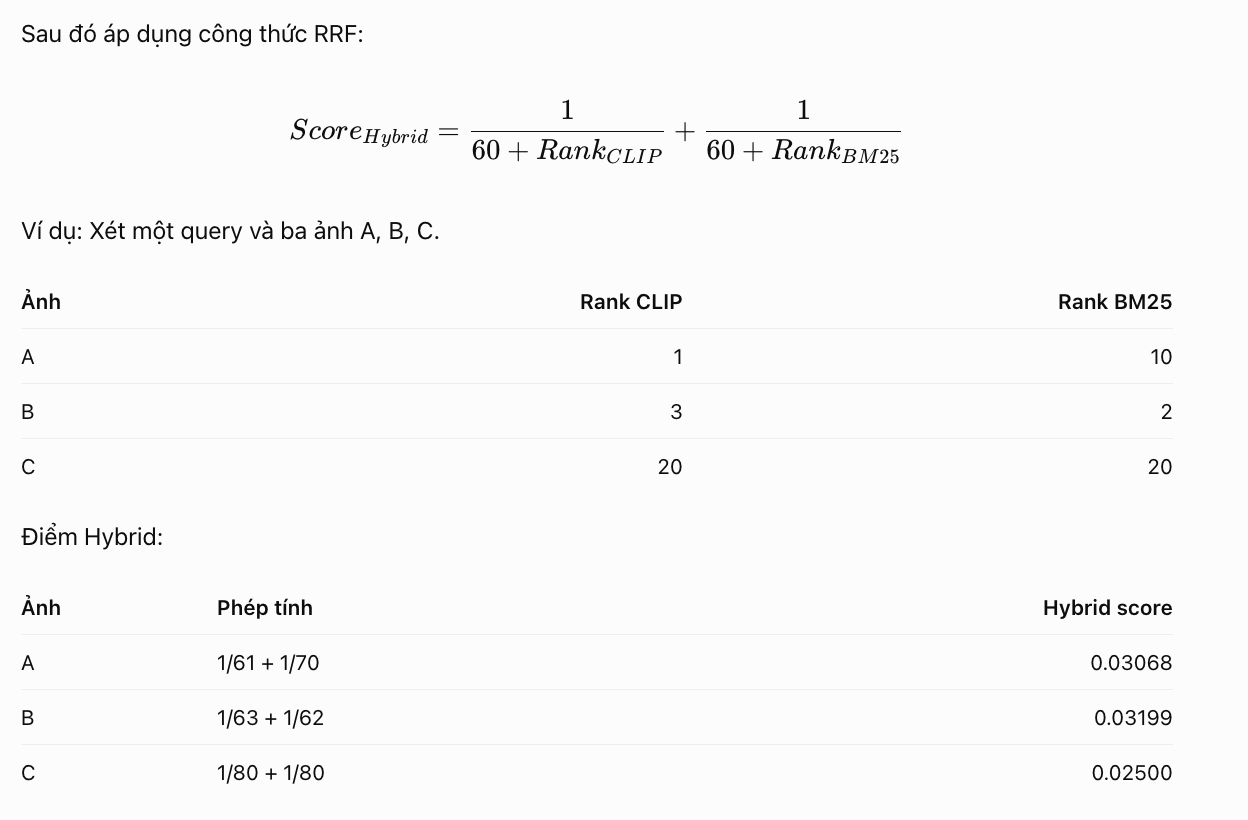


In [8]:
runs = [
    (MODEL, "T2I", score_t2i),
    (MODEL, "T2T", score_t2t),
    ("bm25", "BM25", score_bm25),
    (f"{MODEL} + bm25", "T2I+BM25 (RRF)", score_hybrid),
    (f"{MODEL} + bm25", "T2I+T2T+BM25 (RRF)", score_t2i_t2t_bm25),
    (f"{MODEL} + bm25", "T2T+BM25 (RRF)", score_t2t_bm25),
]
res = pd.DataFrame([{"model": m, "method": name, **evaluate(top_k(s), gt)} for m, name, s in runs])
res.to_csv(f"{ROOT}/artifacts/results/results.csv", index=False)
res


,model,method,R@1,R@5,R@10,MRR@10
0,openai/clip-vit-base-patch32,T2I,0.5367,0.8072,0.8888,0.6529
1,openai/clip-vit-base-patch32,T2T,0.5767,0.8090,0.8814,0.6765
2,bm25,BM25,0.4753,0.7295,0.8108,0.5840
3,openai/clip-vit-base-patch32 + bm25,T2I+BM25 (RRF),0.6093,0.8606,0.9230,0.7159
4,openai/clip-vit-base-patch32 + bm25,T2I+T2T+BM25 (RRF),0.6413,0.8784,0.9402,0.7434
5,openai/clip-vit-base-patch32 + bm25,T2T+BM25 (RRF),0.5667,0.8144,0.8926,0.6739
